# **Nama Anggota Kelompok**
- Ranya Salma Aqila
- Raihan Fawwaz Naufal
- Naila Hariri
- Rubben Siahaan

# **Deskripsi Project Kelompok**
Pada final project ini, kelompok kami mengambil dataset sentiment_analysis.csv, yang berisi teks-teks dari media sosial yang dikategorikan ke dalam tiga sentimen utama: positif, negatif, dan netral.

Tujuan dari project ini adalah untuk melakukan analisis sentimen menggunakan machine learning, khususnya dengan menggunakan model Logistic Regression untuk mengklasifikasikan sentimen teks, serta menggunakan Large Language Model (LLM) untuk melakukan analisis topik pada teks yang telah dikelompokkan berdasarkan sentimen.

# **Langkah 1: Setup Environment dan Persiapan Dataset**
Langkah pertama adalah menginstal pustaka yang dibutuhkan dan mengunggah dataset yang akan digunakan untuk analisis sentimen.

In [1]:
# Instalasi pustaka yang diperlukan
!pip install pandas numpy scikit-learn transformers matplotlib

In [2]:
# Import pustaka yang diperlukan
import pandas as pd  # Untuk manipulasi dan analisis data
import numpy as np  # Untuk operasi numerik
import matplotlib.pyplot as plt  # Untuk visualisasi
from sklearn.model_selection import train_test_split  # Untuk membagi data
from sklearn.feature_extraction.text import TfidfVectorizer  # Untuk representasi teks
from sklearn.linear_model import LogisticRegression  # Untuk model klasifikasi
from sklearn.metrics import classification_report, accuracy_score  # Untuk evaluasi model
from transformers import pipeline  # Untuk zero-shot classification

In [3]:
# Membaca dataset CSV
df = pd.read_csv('/content/drive/MyDrive/FINAL PROJECT MSIB 7 CELERATES/sentiment_analysis.csv')  # Pastikan nama file sesuai

In [4]:
df.head()  # Menampilkan data awal

,Year,Month,Day,Time of Tweet,text,sentiment,Platform
0,2018,8,18,morning,What a great day!!! Looks like dream.,positive,Twitter
1,2018,8,18,noon,"I feel sorry, I miss you here in the sea beach",positive,Facebook
2,2017,8,18,night,Don't angry me,negative,Facebook
3,2022,6,8,morning,We attend in the class just for listening teac...,negative,Facebook
4,2022,6,8,noon,"Those who want to go, let them go",negative,Instagram


# **Langkah 2: Data Cleaning dan Preprocessing**
Pada langkah ini, kita membersihkan data teks dengan:
- Menghapus angka dan tanda baca
- Mengubah teks menjadi huruf kecil
- Menormalkan label sentimen menjadi huruf kecil agar konsisten


In [5]:
df['Cleaned_Text'] = df['text'].str.lower().str.replace(r'[^\w\s]', ' ').str.replace(r'\d+', '', regex=True)
df['sentiment'] = df['sentiment'].str.lower()

In [6]:
# Menampilkan 5 baris pertama setelah preprocessing
df.head()

,Year,Month,Day,Time of Tweet,text,sentiment,Platform,Cleaned_Text
0,2018,8,18,morning,What a great day!!! Looks like dream.,positive,Twitter,what a great day!!! looks like dream.
1,2018,8,18,noon,"I feel sorry, I miss you here in the sea beach",positive,Facebook,"i feel sorry, i miss you here in the sea beach"
2,2017,8,18,night,Don't angry me,negative,Facebook,don't angry me
3,2022,6,8,morning,We attend in the class just for listening teac...,negative,Facebook,we attend in the class just for listening teac...
4,2022,6,8,noon,"Those who want to go, let them go",negative,Instagram,"those who want to go, let them go"


# **Langkah 3: Membagi Data**
- Dataset akan dibagi menjadi data latih (training) dan data uji (testing). Data latih digunakan untuk melatih model, sementara data uji digunakan untuk mengevaluasi performa model

In [7]:
X = df['Cleaned_Text']  # Fitur (teks yang telah dibersihkan)
y = df['sentiment']  # Label sentimen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **Langkah 4: Feature Engineering**
- Pada langkah ini, teks direpresentasikan dalam bentuk numerik menggunakan TF-IDF. Representasi ini diperlukan agar model dapat memproses data teks.

In [8]:
tfidf = TfidfVectorizer(max_features=5000)  # Membatasi hingga 5000 fitur teratas
X_train_tfidf = tfidf.fit_transform(X_train)  # Menerapkan TF-IDF pada data latih
X_test_tfidf = tfidf.transform(X_test)  # Menerapkan TF-IDF pada data uji

# **Langkah 5: Membuat Model Logistic Regression**
Pada langkah ini, kita membangun model Logistic Regression untuk memprediksi sentimen. Logistic Regression adalah algoritma populer untuk klasifikasi data teks.


In [9]:
model = LogisticRegression(max_iter=200)  # Model dengan iterasi maksimum 200
model.fit(X_train_tfidf, y_train)  # Melatih model dengan data latih

LogisticRegression(max_iter=200)

# **Langkah 6: Evaluasi Model**
Pada langkah ini, kita mengevaluasi performa model dengan:
- Akurasi model
- Laporan klasifikasi (precision, recall, F1-score)

In [10]:
y_pred = model.predict(X_test_tfidf)  # Melakukan prediksi pada data uji
accuracy = accuracy_score(y_test, y_pred)  # Menghitung akurasi model
accuracy  # Menampilkan akurasi model

classification_report(y_test, y_pred)  # Menampilkan laporan klasifikasi

'              precision    recall  f1-score   support\n\n    negative       0.74      0.39      0.51        36\n     neutral       0.48      0.87      0.62        30\n    positive       0.81      0.65      0.72        34\n\n    accuracy                           0.62       100\n   macro avg       0.68      0.63      0.62       100\nweighted avg       0.69      0.62      0.61       100\n'

# **Langkah 7: Analisis Topik dengan Zero-shot Classification**
Langkah ini bertujuan untuk menganalisis topik dari teks dengan sentimen positif menggunakan model zero-shot classification dari Hugging Face.


In [11]:
classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")
candidate_labels = ["technology", "entertainment", "business", "others"]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [12]:
positive_texts = df[df['sentiment'] == 'positive']['Cleaned_Text'].sample(5, random_state=42)
topics = positive_texts.apply(lambda text: classifier(text, candidate_labels=candidate_labels)['labels'][0])

In [13]:
topics_df = pd.DataFrame({'Text': positive_texts.values, 'Predicted Topic': topics})
topics_df  # Menampilkan teks dengan topik yang diprediksi

,Text,Predicted Topic
277,*laughs* i`m glad that you have self confiden...,entertainment
412,_x_atl u mean jack barakat`s?! wow so have u e...,entertainment
220,"errors are red but my life is blue, i love ros...",others
167,writing report cards soooo tired but what an ...,entertainment
274,happy b-day! just woke up on this side of ear...,others


# **Langkah 8: Visualisasi Data**
Langkah terakhir adalah membuat visualisasi untuk:
- Distribusi sentimen
- Perbandingan prediksi dengan nilai aktual

In [14]:
# Visualisasi distribusi sentimen
sentiment_counts = df['sentiment'].value_counts()

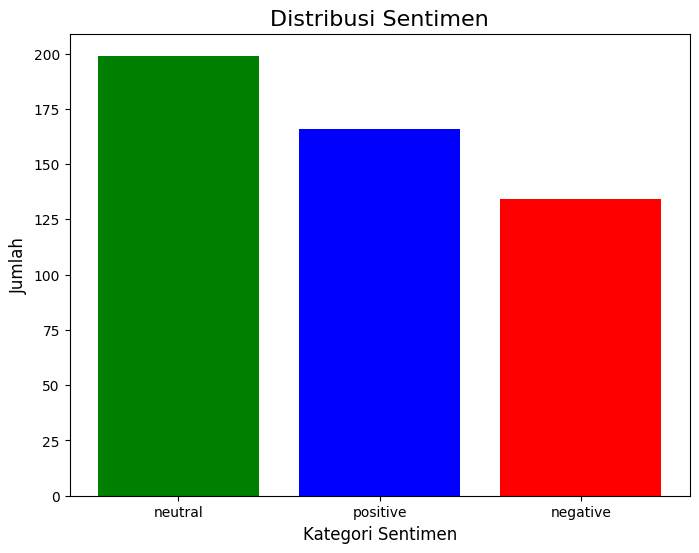

In [15]:
plt.figure(figsize=(8, 6))
plt.bar(sentiment_counts.index, sentiment_counts.values, color=['green', 'blue', 'red'])
plt.title("Distribusi Sentimen", fontsize=16)
plt.xlabel("Kategori Sentimen", fontsize=12)
plt.ylabel("Jumlah", fontsize=12)
plt.show()

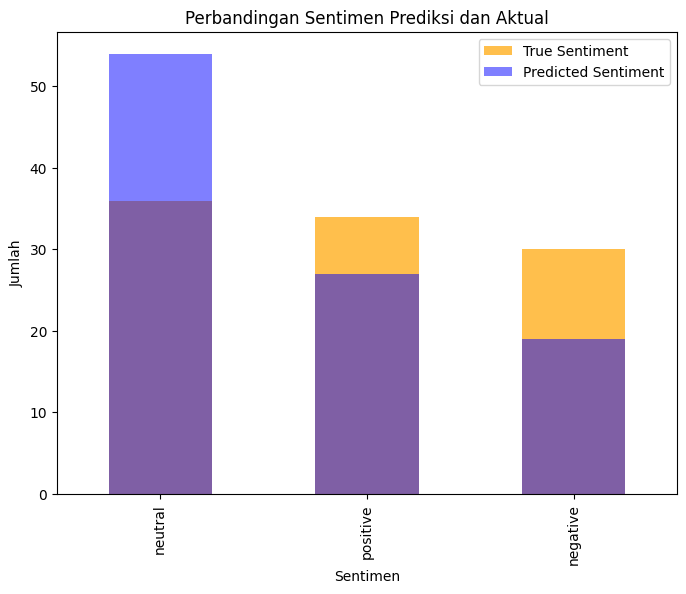

In [16]:
# Perbandingan prediksi vs nilai aktual
predicted_sentiments = pd.DataFrame({'True Sentiment': y_test, 'Predicted Sentiment': y_pred})

fig, ax = plt.subplots(figsize=(8, 6))
predicted_sentiments['True Sentiment'].value_counts().plot(kind='bar', color='orange', alpha=0.7, label='True Sentiment', ax=ax)
predicted_sentiments['Predicted Sentiment'].value_counts().plot(kind='bar', color='blue', alpha=0.5, label='Predicted Sentiment', ax=ax)

plt.legend()
plt.title("Perbandingan Sentimen Prediksi dan Aktual")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah")
plt.show()

# **Kesimpulan**
Kode ini mengimplementasikan alur lengkap analisis sentimen menggunakan dataset sentiment_analysis.csv, mulai dari pembersihan data dengan menghapus karakter dan angka, hingga preprocessing teks dengan mengubahnya menjadi huruf kecil. TF-IDF digunakan untuk representasi numerik, dan Logistic Regression dibangun untuk mengklasifikasikan sentimen. Model dievaluasi menggunakan akurasi dan classification report. Selain itu, zero-shot classification diterapkan untuk menganalisis topik teks dengan sentimen positif.

Hasil visualisasi mencakup distribusi sentimen dan perbandingan prediksi vs aktual menggunakan grafik batang. Secara keseluruhan, kode ini mencakup seluruh pipeline analisis teks dari preprocessing, pemodelan, evaluasi, hingga visualisasi yang memberikan wawasan mendalam tentang data dan kinerja model.